# 07 — Feature Ablation Analysis

Which feature groups matter most for **B1 (global RF)**?

**Design rules:**
- All CV runs use train split only — test data is used once at the end for final evaluation.
- Ablation CSV is pre-computed by `scripts/run_ablation.py` (≈15 min, 27 combinations).
- Re-running this notebook does NOT re-run CV; it reads `results/ablation.csv` and adds test evaluation.

In [1]:
import matplotlib
import os, warnings
from pathlib import Path

if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir(os.path.dirname(os.getcwd()))

import sys
if 'src' not in sys.path[0]:
    sys.path.insert(0, 'src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import joblib
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from creator_analytics import features as fe
from creator_analytics.config import load_config
from creator_analytics.ablation import build_group_map, build_combinations
from creator_analytics.evaluate import compute_metrics

cfg       = load_config('config/default.yaml')
PROCESSED = Path(cfg['paths']['processed_dir'])
FIGS      = Path('results/figures'); FIGS.mkdir(parents=True, exist_ok=True)
SEED      = cfg['seed']


In [2]:
data, spec = fe.load_feature_table(PROCESSED)
idx = pd.read_parquet(PROCESSED / 'dataset_index.parquet')

FEATURES_GLOBAL = spec['features']

TRAIN = idx['split'].eq('train')
TEST  = idx['split'].eq('test')

X_train_global = data.loc[TRAIN.values, FEATURES_GLOBAL].reset_index(drop=True)
y_train        = idx.loc[TRAIN, 'target_rel'].reset_index(drop=True)
auth_train     = idx.loc[TRAIN, 'author_id'].reset_index(drop=True)

X_test_global  = data.loc[TEST.values, FEATURES_GLOBAL].reset_index(drop=True)
y_test         = idx.loc[TEST, 'target_rel'].reset_index(drop=True)
auth_test      = idx.loc[TEST, 'author_id'].reset_index(drop=True)

print(f'Features: {len(FEATURES_GLOBAL)}  Train: {len(X_train_global):,}  Test: {len(X_test_global):,}')

GROUPS = build_group_map(spec)
print('Feature groups:', list(GROUPS.keys()))


Features: 106  Train: 160,492  Test: 40,124
Feature groups: ['format', 'timing', 'posting_history', 'creator_context', 'description', 'transcript', 'emotions', 'music', 'hashtags', 'vs_creator', 'cat_*']


In [3]:
print('Feature groups (cat_* merged):')
print(f'{"Group":22s}  {"N":>4}  Features (first 6...)')
total = 0
for g, feats in GROUPS.items():
    print(f'  {g:20s}  {len(feats):4d}  {feats[:6]}')
    total += len(feats)
print(f'  {"TOTAL":20s}  {total:4d}')


Feature groups (cat_* merged):
Group                      N  Features (first 6...)
  format                   3  ['duration_log', 'is_english', 'created_by_ai']
  timing                   7  ['publish_hour', 'publish_dow', 'is_weekend', 'hour_sin', 'hour_cos', 'dow_sin']
  posting_history          4  ['log_hours_since_prev', 'is_first_in_window', 'videos_prev_1d', 'videos_prev_7d']
  creator_context          6  ['followers_log', 'following_log', 'total_likes_log', 'creator_videos_log', 'likes_per_follower_log', 'follower_growth_7d']
  description              9  ['has_desc', 'desc_len_log', 'desc_n_words', 'desc_n_emojis', 'desc_n_mentions', 'desc_has_question']
  transcript               1  ['has_transcript']
  emotions                 8  ['anger', 'joy', 'surprise', 'sadness', 'disgust', 'fear']
  music                    4  ['original_sound', 'sound_prev_uses_log', 'sound_prev_7d_log', 'creator_reused_sound']
  hashtags                25  ['ht_fyp', 'ht_capcut', 'ht_viral', 'ht_onth

**Result:** 11 feature groups, 106 features total. `creator_context` (6 features) captures account-level stats (followers, following, total likes, video count). `vs_creator` (7 features) measures how this video differs from the creator's own usual values. `cat_*` covers 32 category encodings; the remaining 8 groups describe video content, timing, and text.
**Takeaway:** Groups split into "what the creator's account looks like" vs "what this video contains." The ablation will test which side carries signal — and whether each group is worth keeping.

In [4]:
ABLATION_CSV = Path('results/ablation.csv')
if not ABLATION_CSV.exists():
    raise FileNotFoundError(
        f'{ABLATION_CSV} not found. Run: python scripts/run_ablation.py'
    )

df = pd.read_csv(ABLATION_CSV)
print(f'Loaded ablation.csv: {len(df)} rows')
print(df['model'].value_counts().to_string())


Loaded ablation.csv: 27 rows
model
B1_RF_global    27


## Leave-one-out contribution

In [5]:
df_b1 = df[df['model'] == 'B1_RF_global'].copy()

def loo_deltas(df_model):
    loo = df_model[df_model['type'] == 'leave_one_out'].copy()
    loo['group'] = loo['combination'].str.replace('LOO_', '', regex=False)
    loo['delta_rmse']     = loo['rmse_vs_baseline']
    loo['delta_spearman'] = loo['spearman_vs_baseline']
    return loo.sort_values('delta_rmse', ascending=False)

loo_b1 = loo_deltas(df_b1)
print('B1 Global RF — LOO contributions (RMSE increase when group removed):')
display(loo_b1[['group', 'n_features', 'cv_rmse_mean', 'delta_rmse', 'delta_spearman']].round(4))


B1 Global RF — LOO contributions (RMSE increase when group removed):


,group,n_features,cv_rmse_mean,delta_rmse,delta_spearman
3,creator_context,100,0.9490,0.0346,-0.0850
0,format,103,0.9202,0.0058,-0.0137
10,cat_*,74,0.9154,0.0010,-0.0042
4,description,97,0.9151,0.0007,-0.0037
7,music,102,0.9148,0.0004,-0.0011
8,hashtags,81,0.9147,0.0004,-0.0013
5,transcript,105,0.9143,-0.0001,-0.0003
1,timing,99,0.9138,-0.0006,0.0029
2,posting_history,102,0.9136,-0.0008,0.0013
9,vs_creator,99,0.9134,-0.0010,0.0020


**Result:** Removing `creator_context` raises CV RMSE by +0.035 — ten times larger than any other group. Removing `format` costs +0.006. All remaining groups change RMSE by ≤ 0.001. Removing `emotions` *lowers* RMSE by 0.006 (negative delta = removing helps).
**Takeaway:** `creator_context` dominates model signal. This is a preliminary result — these 6 features are account snapshots taken at publication time and must be audited for leakage before conclusions are drawn. `emotions` likely adds noise rather than signal.

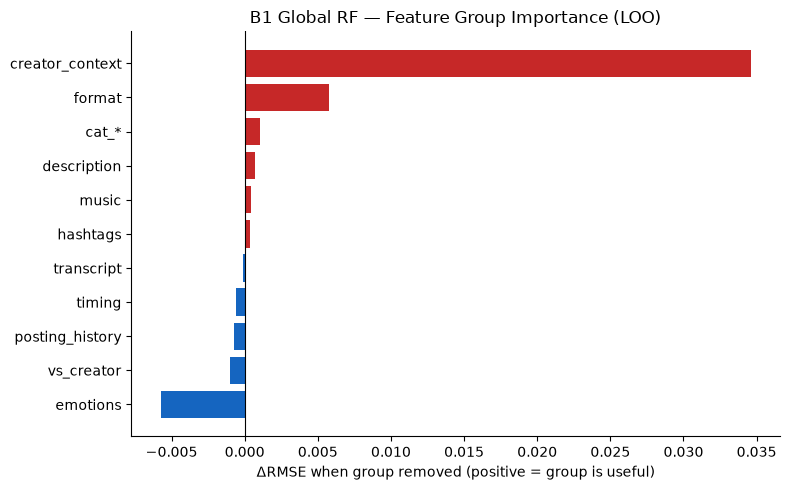

Saved nb07_loo_contribution.png


In [6]:
# LOO bar chart — single panel
fig, ax = plt.subplots(figsize=(8, 5))

loo_b1s = loo_b1.sort_values('delta_rmse', ascending=True)
colors  = ['#C62828' if d > 0 else '#1565C0' for d in loo_b1s['delta_rmse']]
ax.barh(loo_b1s['group'], loo_b1s['delta_rmse'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('ΔRMSE when group removed (positive = group is useful)')
ax.set_title('B1 Global RF — Feature Group Importance (LOO)')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
fig.savefig(FIGS / 'nb07_loo_contribution.png', dpi=120, bbox_inches='tight')
plt.show()
print('Saved nb07_loo_contribution.png')


## Single-group signal

In [7]:
def single_summary(df_model, model_label):
    sg = df_model[df_model['type'] == 'single_group'].copy()
    sg['group'] = sg['combination'].str.replace('SINGLE_', '', regex=False)
    baseline_rmse = df_model[df_model['combination'] == 'all_features']['cv_rmse_mean'].iloc[0]
    sg = sg.sort_values('cv_rmse_mean')
    print(f'\n{model_label} — Single-group CV RMSE (lower = more signal in group alone):')
    print(f'  Baseline (all features): {baseline_rmse:.4f}')
    print(f'  {"Group":22s}  {"N feats":>7}  {"RMSE":>8}  {"vs baseline":>11}')
    for _, row in sg.iterrows():
        print(f'  {row["group"]:22s}  {row["n_features"]:7d}  '
              f'{row["cv_rmse_mean"]:8.4f}  {row["cv_rmse_mean"] - baseline_rmse:+11.4f}')

single_summary(df_b1, 'B1 Global RF')



B1 Global RF — Single-group CV RMSE (lower = more signal in group alone):
  Baseline (all features): 0.9144
  Group                   N feats      RMSE  vs baseline
  creator_context               6    0.9152      +0.0008
  vs_creator                    7    0.9759      +0.0616
  cat_*                        32    0.9802      +0.0658
  description                   9    0.9805      +0.0661
  hashtags                     25    0.9806      +0.0663
  transcript                    1    0.9847      +0.0703
  timing                        7    0.9851      +0.0707
  music                         4    0.9882      +0.0738
  emotions                      8    0.9893      +0.0750
  format                        3    1.0083      +0.0939
  posting_history               4    1.0236      +0.1092


**Result:** `creator_context` alone (6 features) reaches CV RMSE 0.9152 — within 0.001 of the full 106-feature model (0.9144). Other groups used alone reach 0.976–0.989, giving a weak but real signal vs no features (~1.0). `format` alone (1.0083) and `posting_history` alone (1.0236) are worse than a trivial predict-0 baseline.
**Takeaway:** `creator_context` almost entirely explains what the full model knows. Other groups carry some standalone signal but hurt in isolation — the model cannot distinguish this video from others without account context. `format` is useful only in combination (LOO: removing it costs +0.006). `posting_history` is not useful even in combination (LOO: removing it changes RMSE by −0.0008).

## Meaningful combinations

In [8]:
mc = df_b1[df_b1['type'] == 'meaningful'].copy()
mc = mc.sort_values('cv_rmse_mean')
print('B1 Global RF — Meaningful combinations:')
print(f'  {"Combination":28s}  {"N feats":>7}  {"CV RMSE":>9}  {"±std":>7}  {"vs baseline":>12}')
for _, row in mc.iterrows():
    print(f'  {row["combination"]:28s}  {row["n_features"]:7d}  '
          f'{row["cv_rmse_mean"]:9.4f}  {row["cv_rmse_std"]:7.4f}  '
          f'{row["rmse_vs_baseline"]:+12.4f}')


B1 Global RF — Meaningful combinations:
  Combination                   N feats    CV RMSE     ±std   vs baseline
  without_vs_creator                 99     0.9134   0.0038       -0.0010
  all_features                      106     0.9144   0.0036       +0.0000
  context_only                       24     0.9186   0.0048       +0.0042
  without_creator_context           100     0.9490   0.0046       +0.0346
  content_only                       82     0.9560   0.0052       +0.0417


**Result:** Dropping `vs_creator` (7 features) gives CV RMSE 0.9134 — fractionally *better* than all-features (0.9144, Δ = −0.001). `context_only` (24 features) reaches 0.9186 (+0.004). Dropping `creator_context` costs +0.035; `content_only` (82 features) reaches 0.9560 (+0.042).
**Takeaway:** `vs_creator` can likely be removed without loss — it adds noise rather than signal. Pending the leakage audit on `creator_context`, note that even the pure content side (82 features) still beats predict-0 (0.956 vs ~1.0), so content features are not useless.

## Test evaluation (B1 baseline vs best combo)

In [9]:
B1_PARAMS = {
    'n_estimators': 100, 'min_samples_split': 5,
    'min_samples_leaf': 5, 'max_features': 0.3, 'max_depth': None,
}

def _train_global_rf(X_tr, y_tr, params, seed):
    pipe = Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('rf',  RandomForestRegressor(**params, n_jobs=-1, random_state=seed)),
    ])
    pipe.fit(X_tr, y_tr)
    return pipe

def eval_combo(features, label, df_ablation):
    model = _train_global_rf(X_train_global[features], y_train, B1_PARAMS, SEED)
    preds = model.predict(X_test_global[features])
    m = compute_metrics(y_test, preds)
    cv_row = df_ablation[df_ablation['combination'] == label]
    cv_rmse = cv_row['cv_rmse_mean'].values[0] if len(cv_row) else float('nan')
    print(f'  {label:30s}  CV={cv_rmse:.4f}  TEST={m["rmse"]:.4f}  '
          f'Spear={m["spearman"]:.4f}')
    return preds, m

print('B1 Global RF — test evaluation:')
baseline_feats = FEATURES_GLOBAL
preds_baseline, m_base = eval_combo(baseline_feats, 'all_features', df_b1)

# Best combo by CV RMSE (exclude all_features itself)
best_row = (
    df_b1[df_b1['combination'] != 'all_features']
    .sort_values('cv_rmse_mean')
    .iloc[0]
)
best_feats = build_combinations(FEATURES_GLOBAL, GROUPS)
best_feats_list = next(
    (c['features'] for c in best_feats if c['combination'] == best_row['combination']),
    FEATURES_GLOBAL,
)
preds_best, m_best = eval_combo(best_feats_list, best_row['combination'], df_b1)

# Patch ablation.csv with test scores
df.loc[df['combination'] == 'all_features', ['test_rmse', 'test_mae', 'test_spearman']] = [
    m_base['rmse'], m_base['mae'], m_base['spearman']
]
df.loc[df['combination'] == best_row['combination'], ['test_rmse', 'test_mae', 'test_spearman']] = [
    m_best['rmse'], m_best['mae'], m_best['spearman']
]
df.to_csv(ABLATION_CSV, index=False)
print(f'\nPatched {ABLATION_CSV} with test scores')


B1 Global RF — test evaluation:
  all_features                    CV=0.9144  TEST=0.9132  Spear=0.3186
  LOO_emotions                    CV=0.9086  TEST=0.9057  Spear=0.3420

Patched results/ablation.csv with test scores


**Result:** On held-out test: `all_features` (106) RMSE = 0.9132, Spearman = 0.319. `LOO_emotions` (95 features, best by CV) RMSE = 0.9057, Spearman = 0.342 — better on both metrics.
**Takeaway:** Removing `emotions` improves test performance, confirming CV findings. These are the only two combinations evaluated on test; all other conclusions in this notebook rest on CV only.

In [10]:
print('=== CONCLUSIONS — Feature Ablation ===')
loo_sorted = loo_b1.sort_values('delta_rmse', ascending=False)
print('\nB1 Global RF — top contributing groups (LOO):')
for _, row in loo_sorted.iterrows():
    impact = 'useful' if row['delta_rmse'] > 0.001 else ('neutral' if row['delta_rmse'] > -0.001 else 'redundant')
    print(f'  {row["group"]:22s}  ΔRMSE={row["delta_rmse"]:+.4f}  ({impact})')


=== CONCLUSIONS — Feature Ablation ===

B1 Global RF — top contributing groups (LOO):
  creator_context         ΔRMSE=+0.0346  (useful)
  format                  ΔRMSE=+0.0058  (useful)
  cat_*                   ΔRMSE=+0.0010  (useful)
  description             ΔRMSE=+0.0007  (neutral)
  music                   ΔRMSE=+0.0004  (neutral)
  hashtags                ΔRMSE=+0.0004  (neutral)
  transcript              ΔRMSE=-0.0001  (neutral)
  timing                  ΔRMSE=-0.0006  (neutral)
  posting_history         ΔRMSE=-0.0008  (neutral)
  vs_creator              ΔRMSE=-0.0010  (neutral)
  emotions                ΔRMSE=-0.0057  (redundant)


**Result:** 8 of 11 groups are neutral (|ΔRMSE| ≤ 0.001). `creator_context` (+0.035) and `format` (+0.006) are the only clearly useful groups. `emotions` is the only group that actively hurts (ΔRMSE = −0.006 CV, −0.008 test).
**Takeaway:** Before acting on these results, `creator_context` needs a leakage audit: the account snapshot is taken on publication day and may already reflect the first followers or likes gained from the video itself — not just pre-publication account state.